In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

In [2]:
# Load dataset
df = pd.read_csv("D:\Ravi\Intellipat\Python\OnlineRetail.csv", encoding='ISO-8859-1')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,541909.000000,541909,541909.000000,406829.000000,541909.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,17.987795
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,-168469.600000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,3.400000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,9.750000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,17.400000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,168469.600000
std,218.081158,NaN,96.759853,1713.600303,378.810824


In [4]:
# Filter and clean
df = df[df['Quantity'] > 0]
df.dropna(subset=['CustomerID'], inplace=True)
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,397924.000000,397924,397924.000000,397924.000000,397924.000000
mean,13.021823,2011-07-10 23:43:36.912475648,3.116174,15294.315171,22.394749
min,1.000000,2010-12-01 08:26:00,0.000000,12346.000000,0.000000
25%,2.000000,2011-04-07 11:12:00,1.250000,13969.000000,4.680000
50%,6.000000,2011-07-31 14:39:00,1.950000,15159.000000,11.800000
75%,12.000000,2011-10-20 14:33:00,3.750000,16795.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,180.420210,NaN,22.096788,1713.169877,309.055588


In [5]:
print(f"Total Unique Customers: {df['CustomerID'].nunique()}")
print(f"Total Revenue: £{df['TotalPrice'].sum():,.2f}\n")

Total Unique Customers: 4339
Total Revenue: £8,911,407.90



In [6]:
# Top 5 Countries by number of transactions
top_countries = df['Country'].value_counts().head(5)
print("Top 5 Countries by Transactions:")
print(top_countries, "\n")


Top 5 Countries by Transactions:
Country
United Kingdom    354345
Germany             9042
France              8342
EIRE                7238
Spain               2485
Name: count, dtype: int64 



In [7]:
# Top 5 Products by quantity sold
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(5)
print("Top 5 Products by Quantity Sold:")
print(top_products, "\n")

Top 5 Products by Quantity Sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36725
Name: Quantity, dtype: int64 



In [8]:
# Top 5 Customers by revenue
top_customers = df.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False).head(5)
print("Top 5 Customers by Revenue:")
print(top_customers, "\n")

Top 5 Customers by Revenue:
CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
Name: TotalPrice, dtype: float64 



In [9]:
# Repeat customer insights
repeat_customers = df.groupby('CustomerID')['InvoiceNo'].nunique()
repeat_customer_count = (repeat_customers > 1).sum()
total_customers = df['CustomerID'].nunique()
repeat_rate = repeat_customer_count / total_customers

print(f"Repeat Customer Count: {repeat_customer_count}")
print(f"Repeat Customer Rate: {repeat_rate:.2%}\n")


Repeat Customer Count: 2845
Repeat Customer Rate: 65.57%



In [10]:
# Purchase frequency
purchase_frequency = df.groupby('CustomerID')['InvoiceNo'].nunique().describe()
print("Customer Purchase Frequency Summary:")
print(purchase_frequency)

Customer Purchase Frequency Summary:
count    4339.000000
mean        4.271952
std         7.705493
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       210.000000
Name: InvoiceNo, dtype: float64


In [11]:
# Feature Engineering
snapshot_date = df['InvoiceDate'].max()

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': pd.Series.nunique,
    'TotalPrice': 'sum'
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,325,1,77183.60
1,12347.0,1,7,4310.00
2,12348.0,74,4,1797.24
3,12349.0,18,1,1757.55
4,12350.0,309,1,334.40


In [12]:
# Scaling Values
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
rfm_scaled

array([[ 2.33485829e+00, -4.24674873e-01,  8.35963391e+00],
       [-9.05199314e-01,  3.54080191e-01,  2.51046358e-01],
       [-1.75186336e-01, -3.52973410e-02, -2.85464504e-02],
       ...,
       [-8.45198247e-01, -2.94882363e-01, -2.08712435e-01],
       [-8.85198958e-01,  1.52221279e+00,  4.57171586e-03],
       [-4.95192025e-01, -1.65089852e-01, -2.40912314e-02]],
      shape=(4339, 3))

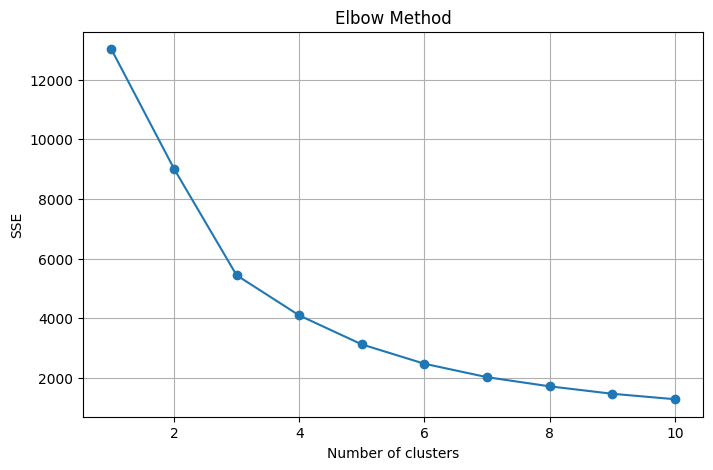

In [13]:
#Elbow Method
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), sse, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.title('Elbow Method')
plt.grid(True)
plt.show()

In [14]:
# K Means Clustering
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
rfm

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,325,1,77183.60,0
1,12347.0,1,7,4310.00,3
2,12348.0,74,4,1797.24,3
3,12349.0,18,1,1757.55,3
4,12350.0,309,1,334.40,1
...,...,...,...,...,...
4334,18280.0,277,1,180.60,1
4335,18281.0,180,1,80.82,1
4336,18282.0,7,2,178.05,3
4337,18283.0,3,16,2094.88,0


In [15]:
# Assigning names to clusters
cluster_names = {
    0: "Loyal Customers",
    1: "Churned Customers",
    2: "Regular Shoppers",
    3: "New or Low-Value Buyers"
}

rfm['Segment'] = rfm['Cluster'].map(cluster_names)
rfm


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,325,1,77183.60,0,Loyal Customers
1,12347.0,1,7,4310.00,3,New or Low-Value Buyers
2,12348.0,74,4,1797.24,3,New or Low-Value Buyers
3,12349.0,18,1,1757.55,3,New or Low-Value Buyers
4,12350.0,309,1,334.40,1,Churned Customers
...,...,...,...,...,...,...
4334,18280.0,277,1,180.60,1,Churned Customers
4335,18281.0,180,1,80.82,1,Churned Customers
4336,18282.0,7,2,178.05,3,New or Low-Value Buyers
4337,18283.0,3,16,2094.88,0,Loyal Customers


In [16]:
#Segment Profiling
segment_profile = rfm.groupby('Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Count'}).reset_index()

segment_profile


,Segment,Recency,Frequency,Monetary,Count
0,Churned Customers,247.564030,1.551789,478.107581,1062
1,Loyal Customers,14.672986,22.047393,12453.225924,211
2,New or Low-Value Buyers,42.910580,3.655748,1349.698298,3053
3,Regular Shoppers,6.384615,82.692308,127338.313846,13


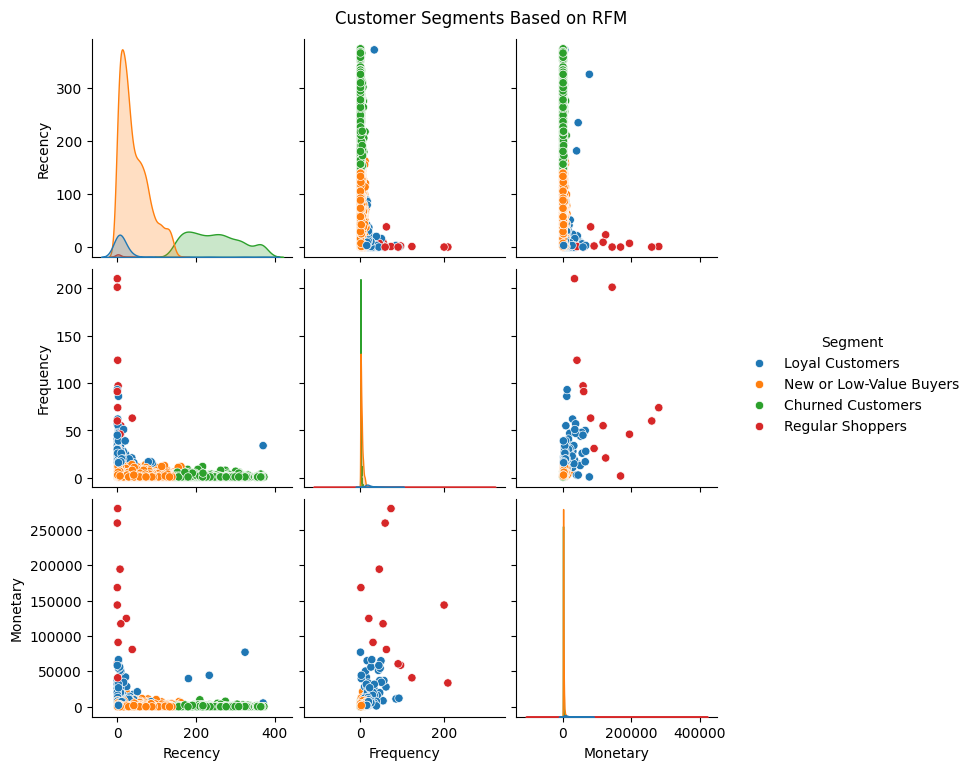

In [17]:
# Cluster Visualization
rfm_plot = rfm.copy()
sns.pairplot(rfm_plot, hue='Segment', vars=['Recency', 'Frequency', 'Monetary'])
plt.suptitle("Customer Segments Based on RFM", y=1.02)
plt.show()